# NeuroScan-AI: Project Walkthrough

## 0. Setup

In [1]:
import os, sys
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # less tf noise

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from src import config as C
from src import data_loader as D
from src import preprocessing as P

pd.set_option("display.max_colwidth", 80)
print("Project root:", PROJECT_ROOT)

Project root: D:\BRAIN TUMOR MRI IMAGE CLASSIFICATION


### Config

In [2]:
cfg = C.get_config()
for section, values in cfg.to_dict().items():
    print(f"[{section}]")
    for k, v in values.items():
        print(f"   {k:<28} {v}")

[split]
   n_folds                      20
   train_folds                  14
   val_folds                    3
   test_folds                   3
   phash_threshold              4
   cross_class_phash_threshold  2
   seed                         42
[data]
   image_size                   (224, 224)
   channels                     3
   batch_size                   16
   seed                         42
[augment]
   rotation_factor              0.027777777777777776
   translation_factor           0.08
   zoom_factor                  0.1
   horizontal_flip              True
   brightness_delta             0.1
   contrast_factor              0.1
[train]
   epochs                       40
   learning_rate                0.001
   early_stopping_patience      8
   reduce_lr_patience           3
   reduce_lr_factor             0.3
   min_lr                       1e-06
   monitor                      val_loss
   use_class_weights            True
   mixed_precision              False
[efficientnet

## 1. The raw dataset

In [3]:
raw = D.discover_images()
class_names = D.get_class_names(raw)  # alphabetical
mapping = D.build_class_mapping(class_names)
print("Classes:", mapping)
raw.head()

11:39:07 | INFO    | data_loader | Discovered 2443 image files in 4 classes


Classes: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}


,filepath,filename,class_name,original_split,source_stem
0,DATASET FOR NEROSCAN AI/test-20261018T183313Z-1-001/test/glioma/Tr-gl_0016_j...,Tr-gl_0016_jpg.rf.99746694ea97fe0b73108832b462d48e.jpg,glioma,test,Tr-gl_0016
1,DATASET FOR NEROSCAN AI/test-20261018T183313Z-1-001/test/glioma/Tr-gl_0018_j...,Tr-gl_0018_jpg.rf.7a670766b8083a1b516a49e241a636bc.jpg,glioma,test,Tr-gl_0018
2,DATASET FOR NEROSCAN AI/test-20261018T183313Z-1-001/test/glioma/Tr-gl_0028_j...,Tr-gl_0028_jpg.rf.8098b9737048aac0dccb1b7c45046894.jpg,glioma,test,Tr-gl_0028
3,DATASET FOR NEROSCAN AI/test-20261018T183313Z-1-001/test/glioma/Tr-gl_0032_j...,Tr-gl_0032_jpg.rf.e1e485b4f909d84c8e24cd26e0ad3c08.jpg,glioma,test,Tr-gl_0032
4,DATASET FOR NEROSCAN AI/test-20261018T183313Z-1-001/test/glioma/Tr-gl_0035_j...,Tr-gl_0035_jpg.rf.7a7c96ab2e6245cf42a0c86b97f81b3e.jpg,glioma,test,Tr-gl_0035


### Roboflow file names

In [4]:
for name in raw["filename"].head(3):
    print(f"{name:<60} ->  {D.source_stem(name)}")
print("\nfiles:", len(raw), "| unique source stems:", raw["source_stem"].nunique())

Tr-gl_0016_jpg.rf.99746694ea97fe0b73108832b462d48e.jpg       ->  Tr-gl_0016
Tr-gl_0018_jpg.rf.7a670766b8083a1b516a49e241a636bc.jpg       ->  Tr-gl_0018
Tr-gl_0028_jpg.rf.8098b9737048aac0dccb1b7c45046894.jpg       ->  Tr-gl_0028

files: 2443 | unique source stems: 2091


original_split,train,val,test,total
class_name,,,,
glioma,564,161,80,805
meningioma,358,124,63,545
no_tumor,335,99,49,483
pituitary,438,118,54,610


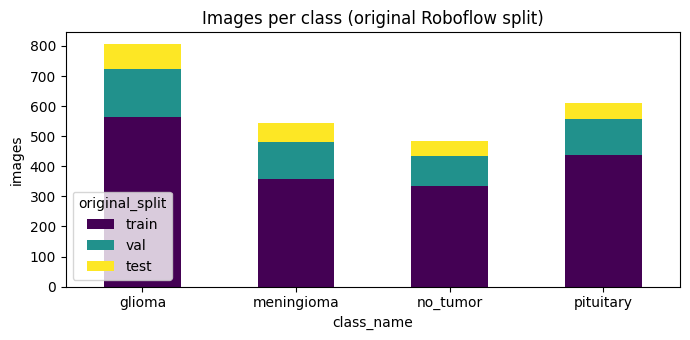

Imbalance ratio (max/min): 1.67


In [5]:
counts = pd.crosstab(raw["class_name"], raw["original_split"])[["train", "val", "test"]]
counts["total"] = counts.sum(axis=1)
display(counts)

ax = counts.drop(columns="total").plot.bar(stacked=True, figsize=(7, 3.5), colormap="viridis")
ax.set_title("Images per class (original Roboflow split)"); ax.set_ylabel("images"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
print(f"Imbalance ratio (max/min): {counts['total'].max() / counts['total'].min():.2f}")

### Sample images

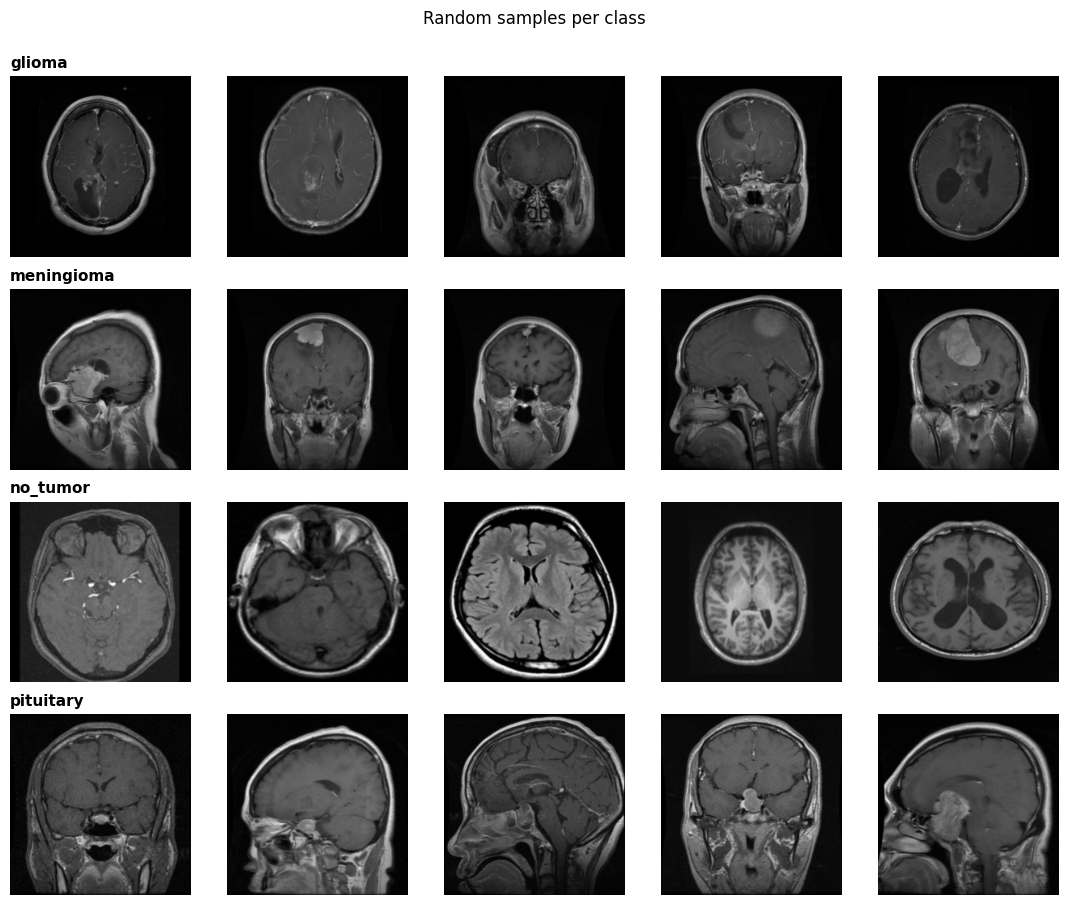

In [6]:
rng = np.random.default_rng(C.SEED)
fig, axes = plt.subplots(len(class_names), 5, figsize=(11, 9))
for r, cls in enumerate(class_names):
    files = raw[raw.class_name == cls]["filepath"].to_numpy()
    for c, fp in enumerate(rng.choice(files, 5, replace=False)):
        axes[r, c].imshow(P.load_image(PROJECT_ROOT / fp))
        axes[r, c].axis("off")
    axes[r, 0].set_title(cls, loc="left", fontsize=11, fontweight="bold")
plt.suptitle("Random samples per class", y=1.0); plt.tight_layout(); plt.show()

## 2. Integrity checks and duplicate detection

In [7]:
info = D.inspect_image(PROJECT_ROOT / raw.filepath.iloc[0])
print({k: info[k] for k in ("readable", "width", "height", "mode", "md5")})
print("pHash bits:", format(int(info["phash"]), "064b"))

{'readable': True, 'width': 640, 'height': 640, 'mode': 'RGB', 'md5': '861012b793b1a5ea0baf3cd31b453d0d'}
pHash bits: 1001011001101001001111100011100101100000101101100111000101100110


### How pHash works

near-duplicate pairs: 704  (grouped: 689)


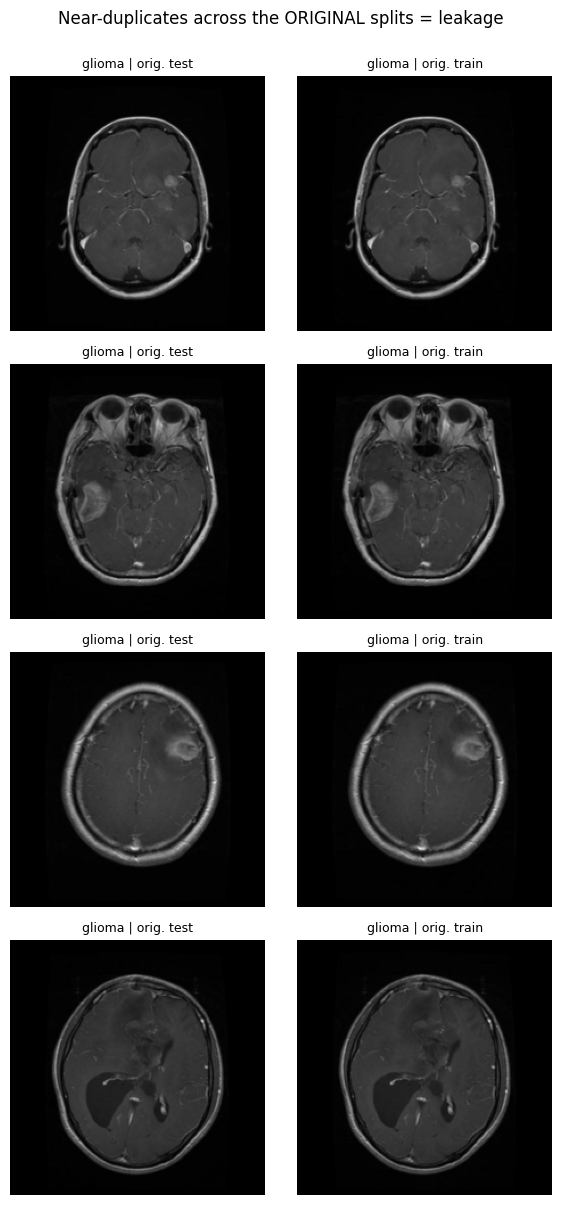

In [8]:
near = pd.read_csv(C.EXPLORATION_DIR / "near_duplicate_pairs.csv")
print(f"near-duplicate pairs: {len(near)}  (grouped: {near.grouped.sum()})")
cross = near[near.split_a != near.split_b].sort_values("hamming").head(4)

fig, axes = plt.subplots(len(cross), 2, figsize=(6, 3 * len(cross)))
for i, (_, r) in enumerate(cross.iterrows()):
    for j, side in enumerate("ab"):
        axes[i, j].imshow(P.load_image(PROJECT_ROOT / r[f"filepath_{side}"]))
        axes[i, j].set_title(f"{r[f'class_{side}']} | orig. {r[f'split_{side}']}", fontsize=9)
        axes[i, j].axis("off")
    # recompute distance
    ha = D.inspect_image(PROJECT_ROOT / r.filepath_a)["phash"]; hb = D.inspect_image(PROJECT_ROOT / r.filepath_b)["phash"]
    axes[i, 0].set_ylabel(f"d={bin(int(ha) ^ int(hb)).count('1')}")
plt.suptitle("Near-duplicates across the ORIGINAL splits = leakage", y=1.0); plt.tight_layout(); plt.show()

### Grouping with Union-Find

In [9]:
toy = pd.DataFrame({
    "filepath": list("abcde"), "class_name": ["glioma"] * 5, "original_split": ["train"] * 5,
    "source_stem": ["s1", "s1", "s2", "s3", "s4"],      # a,b share the original image
    "md5":         ["m1", "m2", "m3", "m3", "m4"],      # c,d are byte-identical
    "phash":       [0, 2**63, 2**62, 2**61, 2**64 - 1],
})
grouped, _ = D.assign_groups(toy, phash_threshold=0)
grouped[["filepath", "source_stem", "md5", "group_id", "group_size"]]

11:39:08 | INFO    | data_loader | Groups: 3 for 5 images | exact-dup pairs: 1 | near-dup pairs (<=0 bits): 0 grouped, 0 cross-class rejected | label-conflict groups: 0


,filepath,source_stem,md5,group_id,group_size
0,a,s1,m1,0,2
1,b,s1,m2,0,2
2,c,s2,m3,1,2
3,d,s3,m3,1,2
4,e,s4,m4,2,1


### Results on the real data

In [10]:
summary = json.loads((C.EXPLORATION_DIR / "dataset_summary.json").read_text())
keys = ["total_files", "unreadable_files", "csv_label_mismatches", "unique_source_stems",
        "duplicate_groups", "near_duplicate_pairs", "original_split_leakage"]
pd.Series({k: summary[k] for k in keys}, name="value").to_frame()

,value
total_files,2443
unreadable_files,0
csv_label_mismatches,0
unique_source_stems,2091
duplicate_groups,1606
near_duplicate_pairs,704
original_split_leakage,"{'source_stem': 164, 'md5': 0, 'group_id': 272}"


## 3. Leakage-safe split (70/15/15)

In [11]:
splits = {s: D.load_split(s) for s in ("train", "val", "test")}
df = pd.concat(splits.values(), ignore_index=True)
D.verify_no_leakage(df)

print("no leakage across splits\n")

tab = pd.crosstab(df.class_name, df.split)[["train", "val", "test"]]
display(tab.assign(total=tab.sum(1)))
display((tab / tab.sum()).round(3).style.set_caption("class proportions within each split"))

no leakage across splits



split,train,val,test,total
class_name,,,,
glioma,563,108,134,805
meningioma,363,94,88,545
no_tumor,332,71,80,483
pituitary,441,87,82,610


split,train,val,test
class_name,,,
glioma,0.331000,0.300000,0.349000
meningioma,0.214000,0.261000,0.229000
no_tumor,0.195000,0.197000,0.208000
pituitary,0.260000,0.242000,0.214000


In [12]:
splits["train"].head(3)

,filepath,class_name,label,split,group_id,group_size,source_stem,original_split,md5,width,height,mode
0,DATASET FOR NEROSCAN AI/test-20261018T183313Z-1-001/test/glioma/Tr-gl_0016_j...,glioma,0,train,0,2,Tr-gl_0016,test,861012b793b1a5ea0baf3cd31b453d0d,640,640,RGB
1,DATASET FOR NEROSCAN AI/test-20261018T183313Z-1-001/test/glioma/Tr-gl_0032_j...,glioma,0,train,3,1,Tr-gl_0032,test,c3cee1d65502f2ae14aad0e75b36fa62,640,640,RGB
2,DATASET FOR NEROSCAN AI/test-20261018T183313Z-1-001/test/glioma/Tr-gl_0037_j...,glioma,0,train,5,2,Tr-gl_0037,test,5755807bdd7ee159771a3ceef631dc51,640,640,RGB


## 4. Preprocessing

In [13]:
batch = P.prepare_batch([PROJECT_ROOT / fp for fp in splits["train"].filepath.head(4)])
print("batch:", batch.shape, batch.dtype, "range:", batch.min(), "→", batch.max())
print(json.dumps(P.preprocessing_spec("efficientnet"), indent=2))

batch: (4, 224, 224, 3) float32 range: 0.0 → 237.0
{
  "input_shape": [
    224,
    224,
    3
  ],
  "color_mode": "RGB",
  "resize": {
    "method": "bilinear",
    "antialias": true,
    "keep_aspect_ratio": false
  },
  "input_dtype": "float32",
  "input_value_range": [
    0,
    255
  ],
  "in_model_normalization": "Keras EfficientNetB0 built-in Rescaling + Normalization (ImageNet)"
}


### Class weights

In [14]:
cw = P.compute_class_weights(splits["train"].label.to_numpy(), len(class_names))
pd.DataFrame({"class": class_names, "train_count": np.bincount(splits["train"].label), "weight": cw.values()}).round(3)

,class,train_count,weight
0,glioma,563,0.754
1,meningioma,363,1.170
2,no_tumor,332,1.279
3,pituitary,441,0.963


### Training data pipeline

In [15]:
import tensorflow as tf
import keras
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "none")

ds = P.make_dataset(splits["val"].head(32), batch_size=16, training=False, cache=False)
x, y = next(iter(ds))
print("one batch ->", x.shape, x.dtype, "labels:", y.numpy())

TensorFlow 2.21.0 | Keras 3.12.4 | GPU: none
one batch -> (16, 224, 224, 3) <dtype: 'float32'> labels: [0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1]


## 5. Data augmentation

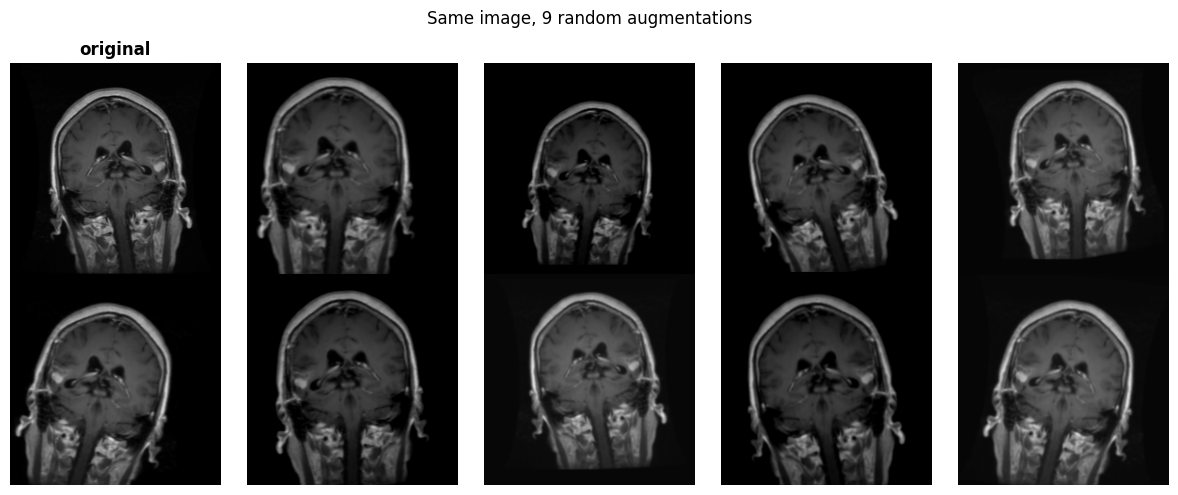

In [16]:
from src.augmentation import build_augmenter

aug = build_augmenter(cfg.augment)
img = P.load_image(PROJECT_ROOT / splits["train"].filepath.iloc[0]).astype("float32")
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes[0, 0].imshow(img.astype("uint8")); axes[0, 0].set_title("original", fontweight="bold")
for ax in axes.flat[1:]:
    ax.imshow(np.clip(aug(img[None], training=True)[0].numpy(), 0, 255).astype("uint8"))
for ax in axes.flat:
    ax.axis("off")
plt.suptitle("Same image, 9 random augmentations"); plt.tight_layout(); plt.show()

## 6. The two models

### 6a. Custom CNN

In [17]:
from src.models.custom_cnn import build_custom_cnn

cnn = build_custom_cnn(num_classes=len(class_names))
cnn.summary(line_length=100)

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)                         │ (None, 224, 224, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ rescale_0_1 (Rescaling)                    │ (None, 224, 224, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_conv1 (Conv2D)                          │ (None, 224, 224, 32)            │               864 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_bn1 (BatchNormalization)                │ (None, 224, 224, 32)            │               128 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_relu1 (ReLU)                            │ (None, 224, 224, 32)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_conv2 (Conv2D)                          │ (None, 224, 224, 32)            │             9,216 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_bn2 (BatchNormalization)                │ (None, 224, 224, 32)            │               128 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_relu2 (ReLU)                            │ (None, 224, 224, 32)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_pool (MaxPooling2D)                     │ (None, 112, 112, 32)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b1_drop (Dropout)                          │ (None, 112, 112, 32)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_conv1 (Conv2D)                          │ (None, 112, 112, 64)            │            18,432 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_bn1 (BatchNormalization)                │ (None, 112, 112, 64)            │               256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_relu1 (ReLU)                            │ (None, 112, 112, 64)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_conv2 (Conv2D)                          │ (None, 112, 112, 64)            │            36,864 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_bn2 (BatchNormalization)                │ (None, 112, 112, 64)            │               256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_relu2 (ReLU)                            │ (None, 112, 112, 64)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_pool (MaxPooling2D)                     │ (None, 56, 56, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b2_drop (Dropout)                          │ (None, 56, 56, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ b3_conv1 (Conv2D)                          │ (None, 56, 56,

 Total params: 1,208,548 (4.61 MB)

 Trainable params: 1,206,628 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

### 6b. EfficientNetB0 transfer learning

In [18]:
from src.models.efficientnet import build_efficientnet, unfreeze_top

def n_trainable(m):
    return sum(int(np.prod(w.shape)) for w in m.trainable_weights)

eff = build_efficientnet(len(class_names), weights=None)
print(f"total params           : {eff.count_params():>10,}")
print(f"stage A trainable      : {n_trainable(eff):>10,}  (head only)")
n_layers = unfreeze_top(eff, cfg.efficientnet.finetune_unfreeze_from)
print(f"stage B trainable      : {n_trainable(eff):>10,}  ({n_layers} backbone layers unfrozen)")
print(f"custom CNN params      : {cnn.count_params():>10,}")

total params           :  4,054,695
stage A trainable      :      5,124  (head only)
stage B trainable      :  3,135,008  (59 backbone layers unfrozen)
custom CNN params      :  1,208,548


## 7. Training

In [19]:
trained = sorted(p.parent.name for p in C.MODELS_DIR.glob("*/model.keras"))
print("Trained models found:", trained or "none yet")
for name in trained:
    s = json.loads((C.MODELS_DIR / name / "training_summary.json").read_text())
    print(f"\n{name}: smoke={s['smoke']} train={s['train_size']} val={s['val_size']} "
          f"selected={s['selected_stage']} time={s['train_time_s']:.0f}s params={s['params']:,}")
    display(pd.read_csv(sorted((C.MODELS_DIR / name).glob("*_log.csv"))[0]).round(4))

Trained models found: ['smoke_custom_cnn']

smoke_custom_cnn: smoke=True train=48 val=24 selected=custom_cnn time=10s params=1,208,548


,epoch,accuracy,epoch_time_s,learning_rate,loss,lr,val_accuracy,val_loss
0,0,0.2917,10.0907,0.001,1.7958,0.001,0.2917,1.4644


## 8. Evaluation

In [20]:
from src.evaluate import compute_metrics

y_true = [0, 0, 0, 0, 1, 1, 2, 2, 3, 3]
y_pred = [0, 0, 0, 0, 0, 1, 2, 3, 3, 3]
m = compute_metrics(y_true, y_pred, class_names)
print(m["classification_report"])
print("confusion matrix (rows = true, cols = predicted):")
pd.DataFrame(m["confusion_matrix"], index=class_names, columns=class_names)

              precision    recall  f1-score   support

      glioma     0.8000    1.0000    0.8889         4
  meningioma     1.0000    0.5000    0.6667         2
    no_tumor     1.0000    0.5000    0.6667         2
   pituitary     0.6667    1.0000    0.8000         2

    accuracy                         0.8000        10
   macro avg     0.8667    0.7500    0.7556        10
weighted avg     0.8533    0.8000    0.7822        10

confusion matrix (rows = true, cols = predicted):


,glioma,meningioma,no_tumor,pituitary
glioma,4,0,0,0
meningioma,1,1,0,0
no_tumor,0,0,1,1
pituitary,0,0,0,2


In [21]:
metric_files = sorted(C.METRICS_DIR.glob("*/test_metrics.json"))
if metric_files:
    rows = []
    for f in metric_files:
        m = json.loads(f.read_text())
        rows.append({"model": f.parent.name, "accuracy": m["accuracy"], "macro_f1": m["macro_f1"],
                     "params": m["params"], "size_mb": m["model_size_mb"],
                     "ms/img (batch 1)": m["inference"]["batch1_ms_median"]})
    display(pd.DataFrame(rows).round(4))
else:
    print("No test metrics yet -> run `python -m src.evaluate --model <name>` after training.")

No test metrics yet -> run `python -m src.evaluate --model <name>` after training.


## 9. Grad-CAM

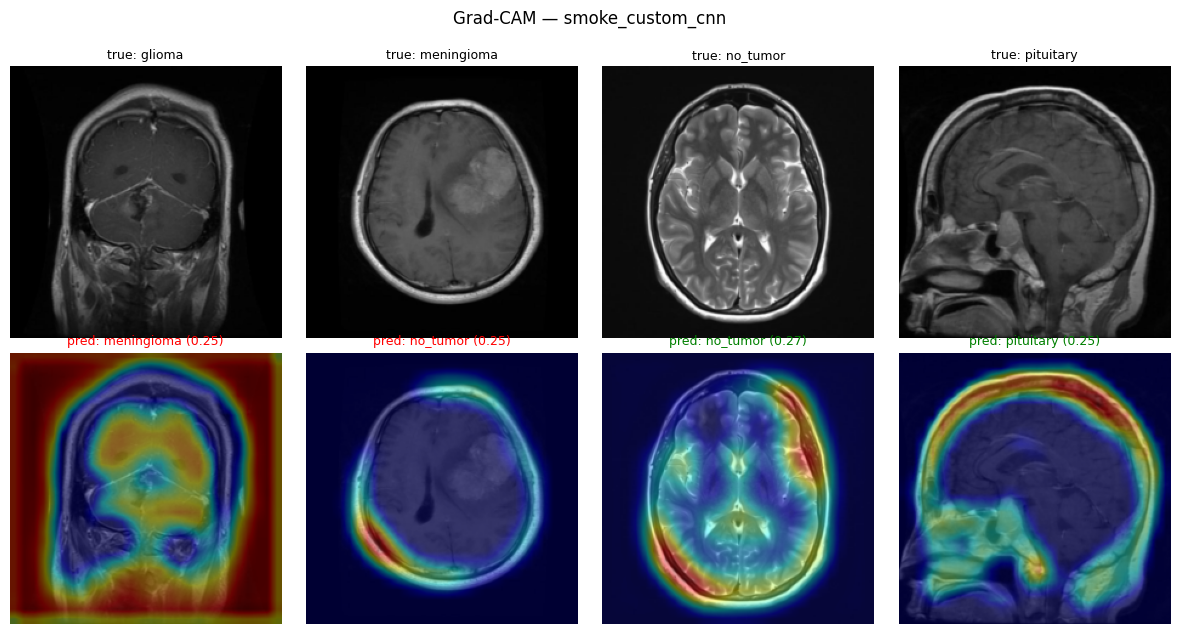

In [22]:
from src.gradcam import gradcam_heatmap, overlay
%matplotlib inline

pref = [n for n in ("efficientnet", "custom_cnn", "smoke_custom_cnn") if n in trained]
if not pref:
    print("No trained model yet — train one first.")
else:
    model_name = pref[0]
    model = keras.models.load_model(C.MODELS_DIR / model_name / "model.keras")
    sample = splits["test"].groupby("class_name").head(1)
    fig, axes = plt.subplots(2, len(sample), figsize=(3 * len(sample), 6.3))
    for i, (_, r) in enumerate(sample.iterrows()):
        img = P.load_image(PROJECT_ROOT / r.filepath)
        cam, ci, probs = gradcam_heatmap(model, img.astype("float32"))
        ok = class_names[ci] == r.class_name
        axes[0, i].imshow(img); axes[0, i].set_title(f"true: {r.class_name}", fontsize=9)
        axes[1, i].imshow(overlay(img, cam))
        axes[1, i].set_title(f"pred: {class_names[ci]} ({probs[ci]:.2f})", fontsize=9, color="green" if ok else "red")
        for a in axes[:, i]:
            a.axis("off")
    plt.suptitle(f"Grad-CAM — {model_name}", y=1.0); plt.tight_layout(); plt.show()

## 10. Predicting a single image

In [23]:
def predict(path, model_name=None):
    model_name = model_name or pref[0]
    mdl = keras.models.load_model(C.MODELS_DIR / model_name / "model.keras")
    names = json.loads((C.MODELS_DIR / model_name / "class_mapping.json").read_text())["class_names"]
    x = P.prepare_batch([path])
    probs = mdl.predict(x, verbose=0)[0]
    return pd.Series(probs, index=names).sort_values(ascending=False)

if pref:
    example = PROJECT_ROOT / splits["test"].filepath.iloc[0]
    print("true label:", splits["test"].class_name.iloc[0])
    display(predict(example).round(4).to_frame("probability"))

true label: glioma


,probability
meningioma,0.2545
glioma,0.2515
pituitary,0.2476
no_tumor,0.2464


## Recap